# MedSAM2 — zero-shot vs box-prompted lesion segmentation

[MedSAM2](https://github.com/bowang-lab/MedSAM2) is a **medical ultrasound/medical-image foundation model** (SAM2, fine-tuned on large medical datasets). It is *promptable*: given a hint (a point or a box) it returns a segmentation mask. We run it two ways on our liver lesions, **with no training of our own**:

- **Zero-shot (center point):** the only prompt is a point at the image centre — the model is told nothing about where the lesion is. A realistic 'blind' baseline.
- **Box-prompted:** we give it the lesion's bounding box.

The question: **does knowing *where* the lesion is (the box) matter?** This separates *localization* (finding the lesion) from *segmentation* (outlining it).

In [1]:
%matplotlib inline
import os, glob, warnings; warnings.simplefilter('ignore')
os.environ.setdefault('USLOC_DATA_ROOT', '/media/ahmed-el-kaffas/20TB-HDD/Puneeth/Dresden_new')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from matplotlib.patches import Rectangle
from usloc import config as C
from usloc.labels import register_case
from usloc.viz import overlay_mask
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor
plt.rcParams.update({'figure.dpi':110,'font.size':9,'axes.titlesize':8,'figure.facecolor':'white'})

ckpt = str(C.DERIVED/'medsam2'/'MedSAM2_latest.pt')
predictor = SAM2ImagePredictor(build_sam2('configs/sam2.1/sam2.1_hiera_t.yaml', ckpt, device='cuda'))
print('MedSAM2 loaded:', ckpt)

def dice(a, b):
    a, b = a>0, b>0; d = a.sum()+b.sum(); return float(2*(a&b).sum()/d) if d else 1.0
def _rgb(img):
    return np.stack([(np.clip(img,0,1)*255).astype('uint8')]*3, -1)
def predict_box(img, box):
    predictor.set_image(_rgb(img))
    m,_,_ = predictor.predict(box=np.asarray(box)[None,:], multimask_output=False)
    return m[0] > 0
def predict_point(img, pt):
    predictor.set_image(_rgb(img))
    m,sc,_ = predictor.predict(point_coords=np.asarray([pt], dtype=np.float32),
                               point_labels=np.array([1]), multimask_output=True)
    return m[int(np.argmax(sc))] > 0


MedSAM2 loaded: /home/puneeth/projects/US-loc-2/data/derived/medsam2/MedSAM2_latest.pt


## Visual comparison
Per case, four panels: **input** (RF-reconstructed B-mode) · **ground truth** (cyan) · **zero-shot** center-point prediction (magenta, point marked ✳) · **box-prompted** prediction (magenta, box in yellow). Dice shown per panel.

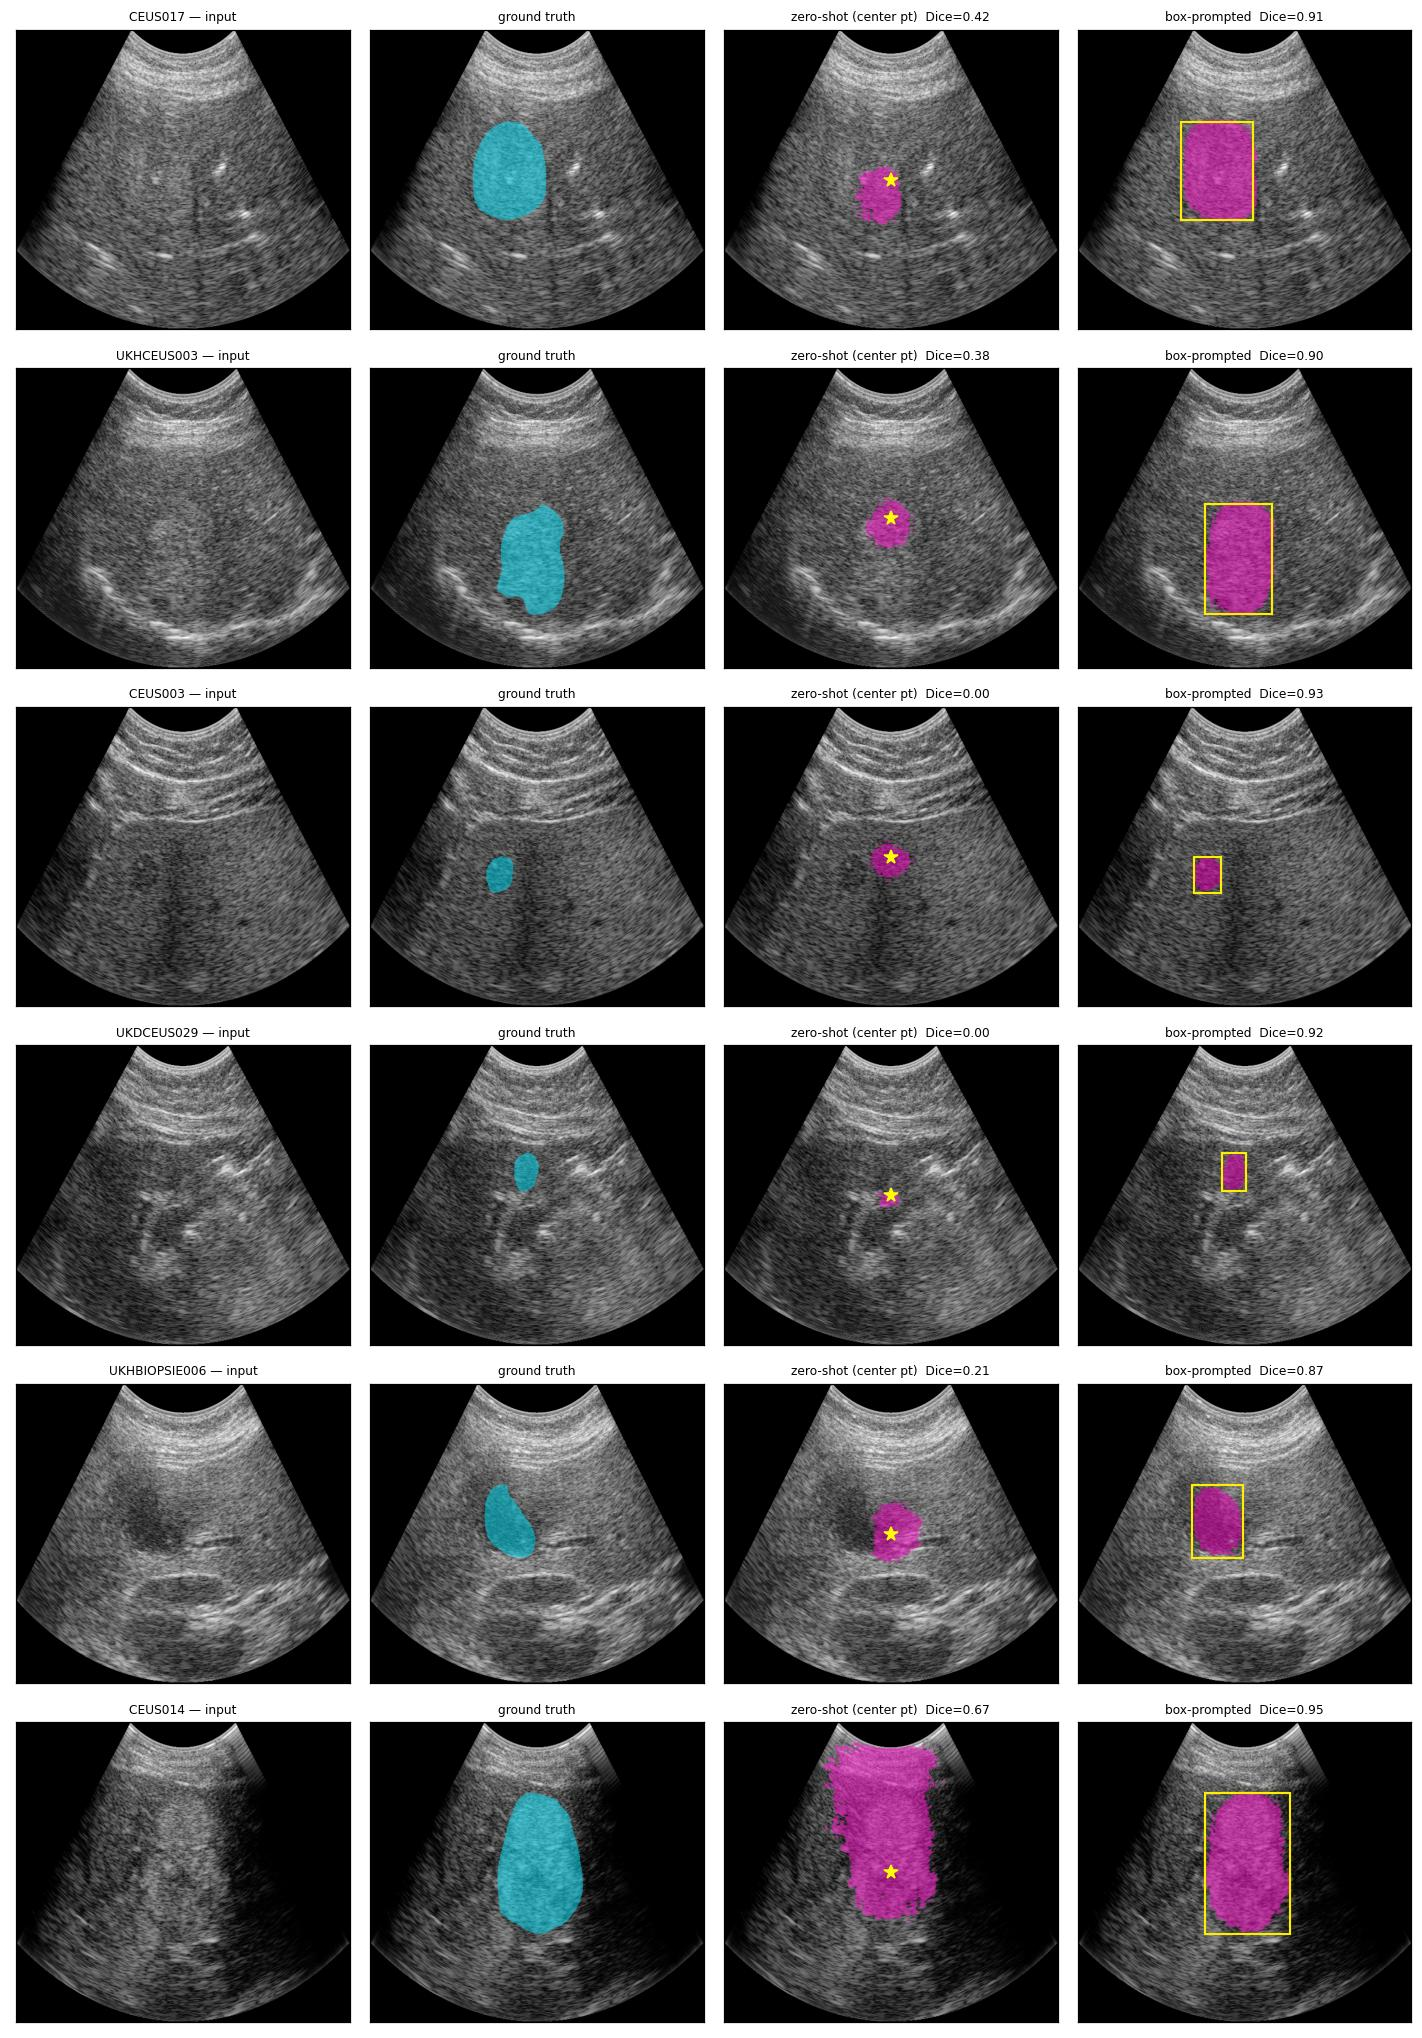

In [2]:
cases = ['CEUS017', 'UKHCEUS003', 'CEUS003', 'UKDCEUS029', 'UKHBIOPSIE006', 'CEUS014']
fig, ax = plt.subplots(len(cases), 4, figsize=(13, 3.1*len(cases)))
for i, case in enumerate(cases):
    s = register_case(case)
    img, gt, box = s.image, s.mask>0, s.bbox
    H, W = img.shape; center = (W/2.0, H/2.0)
    zp = predict_point(img, center); bp = predict_box(img, box)
    row = ax[i]
    row[0].imshow(img, cmap='gray', aspect='auto'); row[0].set_title(f'{case} — input')
    row[1].imshow(overlay_mask(img, gt, (0,229,255), 0.5), aspect='auto'); row[1].set_title('ground truth')
    row[2].imshow(overlay_mask(img, zp, (255,0,200), 0.5), aspect='auto')
    row[2].plot(center[0], center[1], marker='*', color='yellow', ms=9)
    row[2].set_title(f'zero-shot (center pt)  Dice={dice(zp,gt):.2f}')
    row[3].imshow(overlay_mask(img, bp, (255,0,200), 0.5), aspect='auto')
    x0,y0,x1,y1 = box
    row[3].add_patch(Rectangle((x0,y0), x1-x0, y1-y0, fill=False, edgecolor='#ffee00', lw=1.4))
    row[3].set_title(f'box-prompted  Dice={dice(bp,gt):.2f}')
    for a in row: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()


## Quantitative — all 36 Halle external cases
MedSAM2 run on every locked external-test case, both ways.

In [3]:
halle = sorted(os.path.basename(p)[:-9] for p in
               glob.glob(str(C.DERIVED/'nnunet'/'raw'/'Dataset002_LesionRF'/'imagesTs'/'*_0000.png')))
zs, bx = [], []
for case in halle:
    s = register_case(case)
    if s is None or s.bbox is None: continue
    img, gt = s.image, s.mask>0; H, W = img.shape
    zs.append(dice(predict_point(img, (W/2.0, H/2.0)), gt))
    bx.append(dice(predict_box(img, s.bbox), gt))
zs, bx = np.array(zs), np.array(bx)
tab = pd.DataFrame({
    'condition': ['MedSAM2 zero-shot (center point)', 'MedSAM2 box-prompted (GT box)'],
    'mean Dice': [zs.mean(), bx.mean()],
    'median Dice': [np.median(zs), np.median(bx)],
    'detect>0.1': [(zs>0.1).mean(), (bx>0.1).mean()],
    'detect>0.5': [(zs>0.5).mean(), (bx>0.5).mean()],
}).round(3)
print(f'n = {len(zs)} Halle external cases')
display(tab)


n = 36 Halle external cases


,condition,mean Dice,median Dice,detect>0.1,detect>0.5
0,MedSAM2 zero-shot (center point),0.214,0.111,0.5,0.139
1,MedSAM2 box-prompted (GT box),0.883,0.895,1.0,1.000


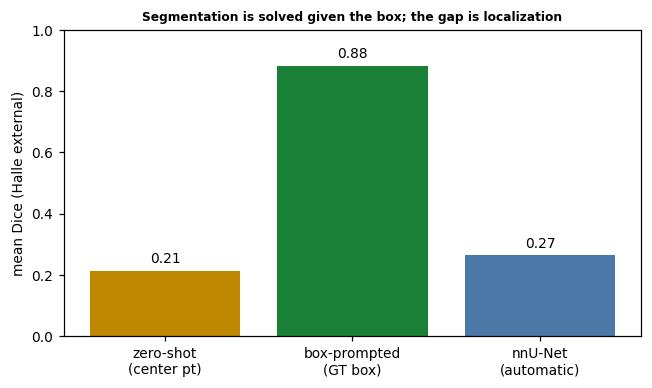

In [4]:
# summary bar chart: the box is what matters (nnU-Net automatic shown for reference)
labels = ['zero-shot\n(center pt)', 'box-prompted\n(GT box)', 'nnU-Net\n(automatic)']
vals = [zs.mean(), bx.mean(), 0.265]
fig, a = plt.subplots(figsize=(6, 3.6))
bars = a.bar(labels, vals, color=['#bf8700', '#1a7f37', '#4C78A8'])
a.set_ylabel('mean Dice (Halle external)'); a.set_ylim(0, 1.0)
a.bar_label(bars, fmt='%.2f', padding=3)
a.set_title('Segmentation is solved given the box; the gap is localization', fontweight='bold')
plt.tight_layout(); plt.show()


## Takeaway
- **Box-prompted MedSAM2 ≈ 0.88 Dice** on the external set, **with no fine-tuning** — segmentation *given the lesion location* is essentially solved.
- **Zero-shot (center point)** is far lower — with no idea where the lesion is, the model segments whatever tissue the point lands on.
- The fully-automatic **nnU-Net** (0.265) and the two-stage nnU-Net→MedSAM2 are limited by the same thing: **localization**. Every bit of localization we gain converts into ~0.88-quality masks.
- **Direction:** invest in *localization* (finding the box) — more data/views, ensembling, a stronger detector — and/or ship a **semi-automatic** tool (clinician draws a rough box → MedSAM2 → 0.88 mask).
- *Caveat:* the ground-truth masks are QuantUS spline polygons, so 0.88 may be near the label ceiling.